In [ ]:
import pandas as pd
df = pd.read_excel("/content/Telco_customer_churn.xlsx")

In [ ]:
print(df.columns)

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='object')


In [ ]:
df["Churn Score"].value_counts()

,count
Churn Score,
80,151
71,148
77,145
67,143
68,141
...,...
88,33
9,3
8,2


In [ ]:
df["Churn Label"].value_counts()

,count
Churn Label,
No,5174
Yes,1869


In [ ]:
df.isnull().sum()

,0
CustomerID,0
Count,0
Country,0
State,0
City,0
Zip Code,0
Lat Long,0
Latitude,0
Longitude,0
Gender,0


In [ ]:
df.isna().sum().sum()

np.int64(5174)

In [ ]:
df.dtypes

,0
CustomerID,object
Count,int64
Country,object
State,object
City,object
Zip Code,int64
Lat Long,object
Latitude,float64
Longitude,float64
Gender,object


In [ ]:
df["Total Charges"].dtype

dtype('O')

In [ ]:
df[df["Total Charges"].str.strip() == ""]

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
2234,4472-LVYGI,1,United States,California,San Bernardino,92408,"34.084909, -117.258107",34.084909,-117.258107,Female,...,Two year,Yes,Bank transfer (automatic),52.55,,No,0,36,2578,NaN
2438,3115-CZMZD,1,United States,California,Independence,93526,"36.869584, -118.189241",36.869584,-118.189241,Male,...,Two year,No,Mailed check,20.25,,No,0,68,5504,NaN
2568,5709-LVOEQ,1,United States,California,San Mateo,94401,"37.590421, -122.306467",37.590421,-122.306467,Female,...,Two year,No,Mailed check,80.85,,No,0,45,2048,NaN
2667,4367-NUYAO,1,United States,California,Cupertino,95014,"37.306612, -122.080621",37.306612,-122.080621,Male,...,Two year,No,Mailed check,25.75,,No,0,48,4950,NaN
2856,1371-DWPAZ,1,United States,California,Redcrest,95569,"40.363446, -123.835041",40.363446,-123.835041,Female,...,Two year,No,Credit card (automatic),56.05,,No,0,30,4740,NaN
4331,7644-OMVMY,1,United States,California,Los Angeles,90029,"34.089953, -118.294824",34.089953,-118.294824,Male,...,Two year,No,Mailed check,19.85,,No,0,53,2019,NaN
4687,3213-VVOLG,1,United States,California,Sun City,92585,"33.739412, -117.173334",33.739412,-117.173334,Male,...,Two year,No,Mailed check,25.35,,No,0,49,2299,NaN
5104,2520-SGTTA,1,United States,California,Ben Lomond,95005,"37.078873, -122.090386",37.078873,-122.090386,Female,...,Two year,No,Mailed check,20.00,,No,0,27,3763,NaN
5719,2923-ARZLG,1,United States,California,La Verne,91750,"34.144703, -117.770299",34.144703,-117.770299,Male,...,One year,Yes,Mailed check,19.70,,No,0,69,4890,NaN
6772,4075-WKNIU,1,United States,California,Bell,90201,"33.970343, -118.171368",33.970343,-118.171368,Female,...,Two year,No,Mailed check,73.35,,No,0,44,2342,NaN


In [ ]:
(df["Total Charges"].str.strip() == "").sum()

np.int64(11)

In [ ]:
df_clean=df.copy()

In [ ]:
df_clean["Total Charges"] = df_clean["Total Charges"].replace("",pd.NA)

In [ ]:
df_clean["Total Charges"] = pd.to_numeric(
    df_clean["Total Charges"],
    errors = "coerce"
)

In [ ]:
df_clean["Total Charges"].dtypes

dtype('float64')

In [ ]:
df_clean["Total Charges"].isnull().sum()

np.int64(11)

In [ ]:
df_clean[df_clean["Total Charges"].isnull()][
    ["CustomerID", "Tenure Months", "Monthly Charges", "Total Charges", "Churn Label"]
]

,CustomerID,Tenure Months,Monthly Charges,Total Charges,Churn Label
2234,4472-LVYGI,0,52.55,NaN,No
2438,3115-CZMZD,0,20.25,NaN,No
2568,5709-LVOEQ,0,80.85,NaN,No
2667,4367-NUYAO,0,25.75,NaN,No
2856,1371-DWPAZ,0,56.05,NaN,No
4331,7644-OMVMY,0,19.85,NaN,No
4687,3213-VVOLG,0,25.35,NaN,No
5104,2520-SGTTA,0,20.00,NaN,No
5719,2923-ARZLG,0,19.70,NaN,No
6772,4075-WKNIU,0,73.35,NaN,No


In [ ]:
df_clean["Total Charges"] = df_clean["Total Charges"].fillna(0)

In [ ]:
df_clean["Total Charges"].isnull().sum()

np.int64(0)

In [ ]:
df_clean["CustomerID"].duplicated().sum()

np.int64(0)

In [ ]:
df_clean.duplicated().sum()

np.int64(0)

In [ ]:
df_clean["Churn Label"].value_counts()

,count
Churn Label,
No,5174
Yes,1869


In [ ]:
Churn_percentage = (df_clean["Churn Label"].value_counts(normalize=True)*100)
print(Churn_percentage)

Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [ ]:
df_clean.shape

(7043, 33)

In [ ]:
df_clean.columns.tolist()

['CustomerID',
 'Count',
 'Country',
 'State',
 'City',
 'Zip Code',
 'Lat Long',
 'Latitude',
 'Longitude',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Tenure Months',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charges',
 'Total Charges',
 'Churn Label',
 'Churn Value',
 'Churn Score',
 'CLTV',
 'Churn Reason']

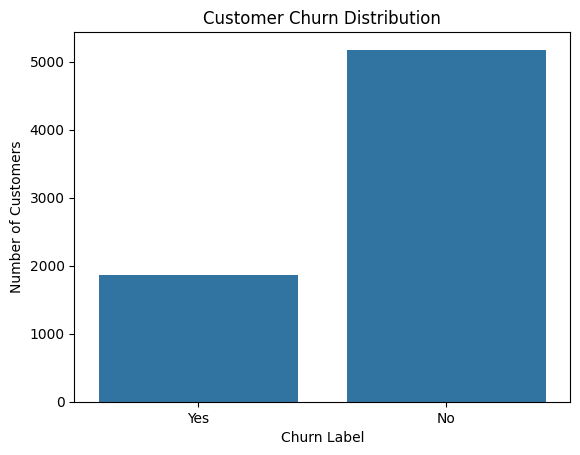

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df_clean,x = "Churn Label")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Label")
plt.ylabel("Number of Customers")
plt.show()

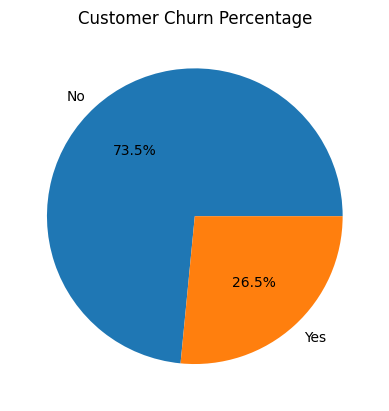

In [ ]:
df_clean["Churn Label"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Customer Churn Percentage")
plt.ylabel("")

plt.show()

In [ ]:
contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn Label"],
    normalize = "index"
)*100

print(contract_churn)

Churn Label            No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


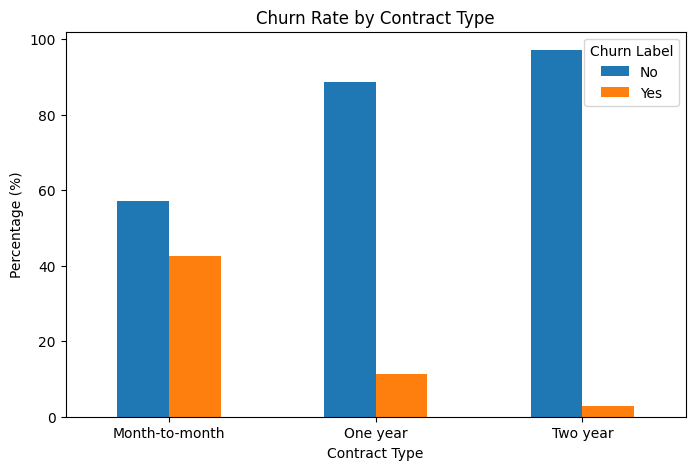

In [ ]:
contract_churn.plot(
    kind="bar",
    figsize=(8,5)

)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.show()

Churn vs tenure

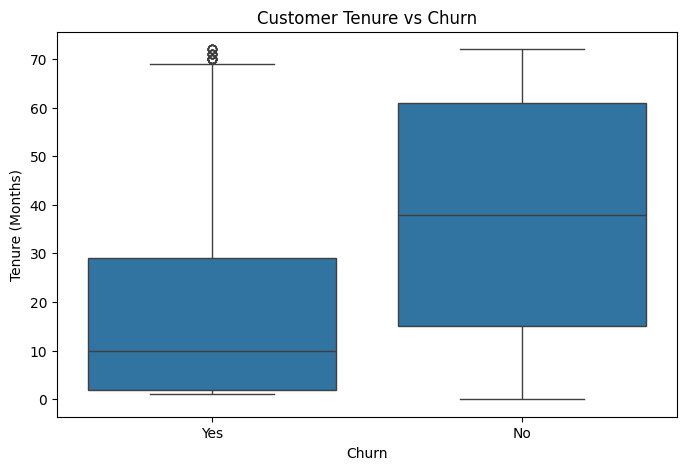

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df_clean,
    x="Churn Label",
    y="Tenure Months"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

monthly charges vs churn

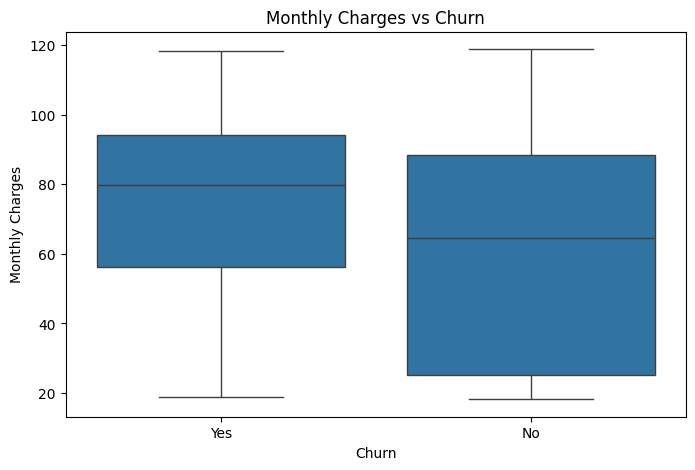

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df_clean,
    x="Churn Label",
    y="Monthly Charges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

In [ ]:
payment_churn = pd.crosstab(
    df_clean["Payment Method"],
    df_clean["Churn Label"],
    normalize = "index"
)*100

print(payment_churn)

Churn Label                       No        Yes
Payment Method                                 
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


In [ ]:
payment_churn_rate = (
    df_clean.groupby("Payment Method")["Churn Value"]
    .mean()
    .sort_values(ascending=False)
)

print(payment_churn_rate * 100)

Payment Method
Electronic check             45.285412
Mailed check                 19.106700
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Name: Churn Value, dtype: float64


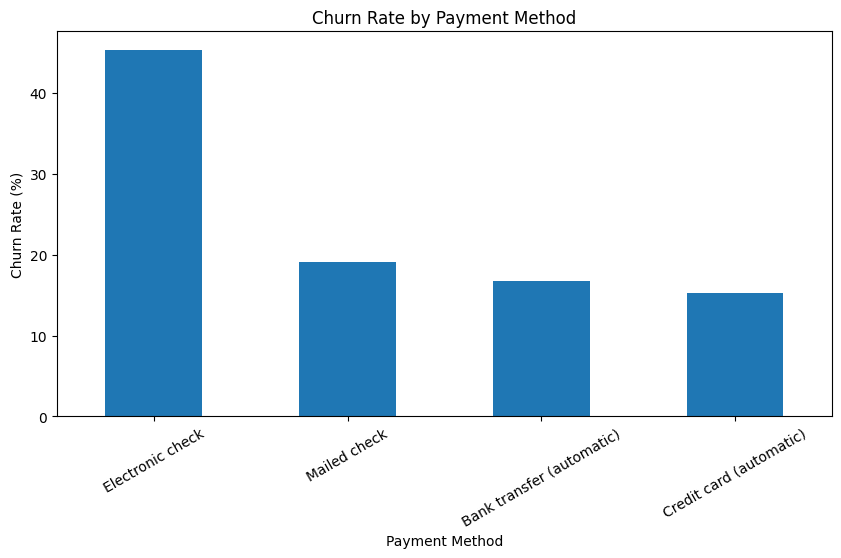

In [ ]:
payment_churn_rate.mul(100).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)

plt.show()

In [ ]:
internet_churn = pd.crosstab(
    df_clean["Internet Service"],
    df_clean["Churn Label"],
    normalize="index"
) * 100

print(internet_churn)

Churn Label              No        Yes
Internet Service                      
DSL               81.040892  18.959108
Fiber optic       58.107235  41.892765
No                92.595020   7.404980


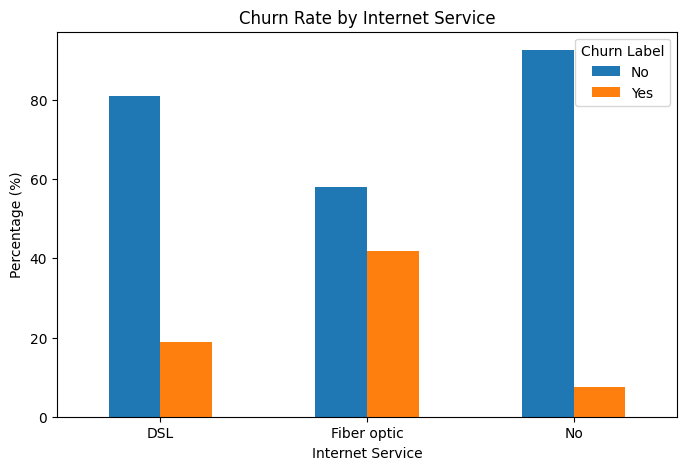

In [ ]:
internet_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)

plt.show()

In [ ]:
security_churn = pd.crosstab(
    df_clean["Online Security"],
    df_clean["Churn Label"],
    normalize="index"
) * 100

print(security_churn)

Churn Label                 No        Yes
Online Security                          
No                   58.233276  41.766724
No internet service  92.595020   7.404980
Yes                  85.388806  14.611194


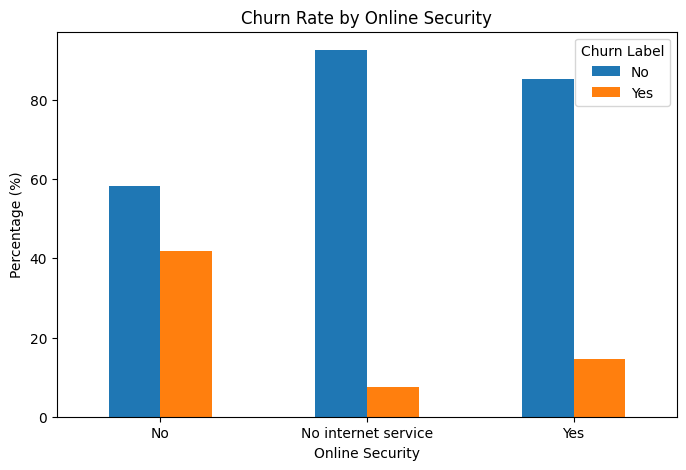

In [ ]:
security_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)

plt.show()

In [ ]:
support_churn = pd.crosstab(
    df_clean["Tech Support"],
    df_clean["Churn Label"],
    normalize="index"
) * 100

print(support_churn)

Churn Label                 No        Yes
Tech Support                             
No                   58.364526  41.635474
No internet service  92.595020   7.404980
Yes                  84.833659  15.166341


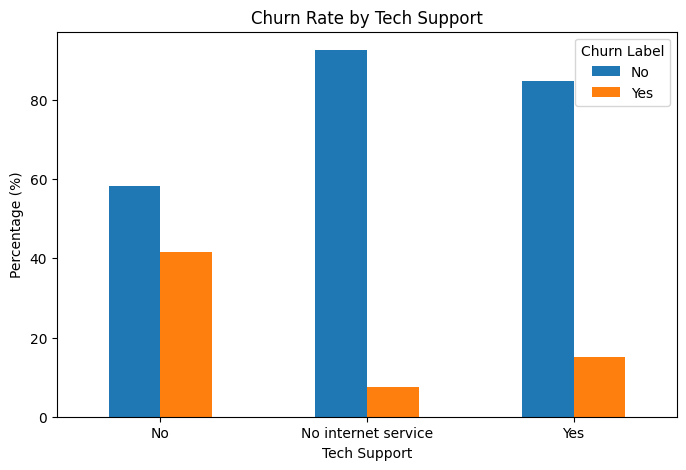

In [ ]:
support_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)

plt.show()

In [ ]:
senior_churn = pd.crosstab(
    df_clean["Senior Citizen"],
    df_clean["Churn Label"],
    normalize="index"
) * 100

print(senior_churn)

Churn Label            No        Yes
Senior Citizen                      
No              76.393832  23.606168
Yes             58.318739  41.681261


In [ ]:
dependent_churn = pd.crosstab(
    df_clean["Dependents"],
    df_clean["Churn Label"],
    normalize="index"
) * 100

print(dependent_churn)

Churn Label         No        Yes
Dependents                       
No           67.448301  32.551699
Yes          93.484942   6.515058


In [ ]:
partner_churn = pd.crosstab(
    df_clean["Partner"],
    df_clean["Churn Label"],
    normalize="index"
) * 100

print(partner_churn)

Churn Label         No        Yes
Partner                          
No           67.042021  32.957979
Yes          80.335097  19.664903


In [ ]:
drop_columns = [
    "CustomerID",
    "Count",
    "Churn Label",
    "Churn Value",
    "Churn Score",
    "Churn Reason",
    "CLTV"
]

model_df = df_clean.drop(columns=drop_columns)

In [ ]:
model_df.head()

,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,...,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges
0,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,...,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,...,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65
2,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,...,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50
3,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,...,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05
4,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,...,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30


In [ ]:
model_df.shape

(7043, 26)

In [ ]:
X = model_df

y = df_clean["Churn Label"]

In [ ]:
X.shape, y.shape

((7043, 26), (7043,))

In [ ]:
drop_columns =[
    "CustomerID",
    "Count",
    "Churn Label",
    "Churn Value",
    "Churn Score",
    "Churn Reason",
    "CLTV"
]

model_df = df_clean.drop(columns=drop_columns)

X = model_df
y = df_clean["Churn Label"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (7043, 26)
y shape: (7043,)


In [ ]:
geo_columns = [
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude"
]

model_df = df_clean.drop(
    columns=drop_columns + geo_columns
)

In [ ]:
X = model_df

print("X shape:", X.shape)

X shape: (7043, 19)


Identify numerical and categorical feature

In [ ]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\ncategorical features:")
print(categorical_features)

Numerical features:
['Tenure Months', 'Monthly Charges', 'Total Charges']

categorical features:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


In [ ]:
y = y.map({
    "No": 0,
    "Yes": 1
})

print(y.value_counts())

Churn Label
0    5174
1    1869
Name: count, dtype: int64


In [ ]:
print(y.dtype)

int64


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
y = df_clean["Churn Label"]
y = y.map({
    "No": 0,
    "Yes": 1
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [ ]:
print("Original:")
print(y.value_counts(normalize=True) * 100)

print("\nTraining:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting:")
print(y_test.value_counts(normalize=True) * 100)

Original:
Churn Label
0    73.463013
1    26.536987
Name: proportion, dtype: float64

Training:
Churn Label
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Testing:
Churn Label
0    73.456352
1    26.543648
Name: proportion, dtype: float64


In [ ]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical:", numerical_features)
print("Categorical:", categorical_features)

Numerical: ['Tenure Months', 'Monthly Charges', 'Total Charges']
Categorical: ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [ ]:
numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [ ]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [ ]:
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", logistic_model)
    ]
)

In [ ]:
logistic_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Tenure Months',
                                                   'Monthly Charges',
                                                   'Total Charges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender', 'Senior Citizen',
                                                   'Partner', 'Dependents',
                                                   'Phone Service',
                                                   'Multiple Lines',
                                                   'Internet Service',
                                                   'Online Security',
                                                   'Online Backup',
                                                   'Device Protection',
                                                   'Tech Support',
                                                   'Streaming TV',
                                                   'Streaming Movies',
                                                   'Contract',
                                                   'Paperless Billing',
                                                   'Payment Method'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [ ]:
y_pred = logistic_pipeline.predict(X_test)

In [ ]:
y_prob = logistic_pipeline.predict_proba(X_test)[:, 1]

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC-AUC  :", roc_auc)

Accuracy : 0.8019872249822569
Precision: 0.6435045317220544
Recall   : 0.56951871657754
F1 Score : 0.6042553191489362
ROC-AUC  : 0.8488671885091322


In [ ]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[917 118]
 [161 213]]


In [ ]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.64      0.57      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409



In [ ]:
feature_names = (
    logistic_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = (
    logistic_pipeline
    .named_steps["model"]
    .coef_[0]
)

In [ ]:
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

In [ ]:
coef_df["Absolute_Coefficient"] = (
    coef_df["Coefficient"].abs()
)

coef_df = coef_df.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

In [ ]:
coef_df.head(15)

,Feature,Coefficient,Absolute_Coefficient
0,num__Tenure Months,-1.270244,1.270244
10,cat__Dependents_Yes,-0.989424,0.989424
39,cat__Contract_Two year,-0.734672,0.734672
9,cat__Dependents_No,0.645479,0.645479
16,cat__Internet Service_DSL,-0.608835,0.608835
37,cat__Contract_Month-to-month,0.563585,0.563585
17,cat__Internet Service_Fiber optic,0.550165,0.550165
2,num__Total Charges,0.521700,0.521700
1,num__Monthly Charges,-0.497754,0.497754
40,cat__Paperless Billing_No,-0.350410,0.350410


In [ ]:
coef_df.tail(15)

,Feature,Coefficient,Absolute_Coefficient
4,cat__Gender_Male,-0.165549,0.165549
6,cat__Senior Citizen_Yes,-0.160236,0.160236
36,cat__Streaming Movies_Yes,0.155942,0.155942
19,cat__Online Security_No,0.132466,0.132466
11,cat__Phone Service_No,-0.126135,0.126135
14,cat__Multiple Lines_No phone service,-0.126135,0.126135
45,cat__Payment Method_Mailed check,-0.117796,0.117796
28,cat__Tech Support_No,0.114846,0.114846
15,cat__Multiple Lines_Yes,0.081648,0.081648
24,cat__Online Backup_Yes,-0.066118,0.066118


In [ ]:
OneHotEncoder(
    handle_unknown="ignore",
    drop="first"
)

OneHotEncoder(drop='first', handle_unknown='ignore')

In [ ]:
OneHotEncoder(drop="first")

OneHotEncoder(drop='first')

In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor_v2 = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        )
    ]
)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model_v2 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [ ]:
logistic_pipeline_v2 = Pipeline(
    steps=[
        ("preprocessor", preprocessor_v2),
        ("model", logistic_model_v2)
    ]
)

In [ ]:
logistic_pipeline_v2.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Tenure Months',
                                                   'Monthly Charges',
                                                   'Total Charges']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Gender', 'Senior Citizen',
                                                   'Partner', 'Dependents',
                                                   'Phone Service',
                                                   'Multiple Lines',
                                                   'Internet Service',
                                                   'Online Security',
                                                   'Online Backup',
                                                   'Device Protection',
                                                   'Tech Support',
                                                   'Streaming TV',
                                                   'Streaming Movies',
                                                   'Contract',
                                                   'Paperless Billing',
                                                   'Payment Method'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [ ]:
y_pred_v2 = logistic_pipeline_v2.predict(X_test)

y_prob_v2 = logistic_pipeline_v2.predict_proba(
    X_test
)[:, 1]

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

accuracy_v2 = accuracy_score(y_test, y_pred_v2)
precision_v2 = precision_score(y_test, y_pred_v2)
recall_v2 = recall_score(y_test, y_pred_v2)
f1_v2 = f1_score(y_test, y_pred_v2)
roc_auc_v2 = roc_auc_score(y_test, y_prob_v2)

print("Logistic Regression v2")
print("---------------------")
print("Accuracy :", accuracy_v2)
print("Precision:", precision_v2)
print("Recall   :", recall_v2)
print("F1 Score :", f1_v2)
print("ROC-AUC  :", roc_auc_v2)

Logistic Regression v2
---------------------
Accuracy : 0.8019872249822569
Precision: 0.6426426426426426
Recall   : 0.5721925133689839
F1 Score : 0.6053748231966054
ROC-AUC  : 0.8490531917641891


In [ ]:
cm_v2 = confusion_matrix(
    y_test,
    y_pred_v2
)

print(cm_v2)

[[916 119]
 [160 214]]


In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression v1",
        "Logistic Regression v2"
    ],
    "Accuracy": [
        accuracy,
        accuracy_v2
    ],
    "Precision": [
        precision,
        precision_v2
    ],
    "Recall": [
        recall,
        recall_v2
    ],
    "F1": [
        f1,
        f1_v2
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_v2
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression v1,0.801987,0.643505,0.569519,0.604255,0.848867
1,Logistic Regression v2,0.801987,0.642643,0.572193,0.605375,0.849053


In [ ]:
feature_names_v2 = (
    logistic_pipeline_v2
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients_v2 = (
    logistic_pipeline_v2
    .named_steps["model"]
    .coef_[0]
)

coef_df_v2 = pd.DataFrame({
    "Feature": feature_names_v2,
    "Coefficient": coefficients_v2
})

coef_df_v2["Absolute_Coefficient"] = (
    coef_df_v2["Coefficient"].abs()
)

coef_df_v2 = coef_df_v2.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

coef_df_v2.head(20)

,Feature,Coefficient,Absolute_Coefficient
6,cat__Dependents_Yes,-1.614467,1.614467
25,cat__Contract_Two year,-1.287759,1.287759
0,num__Tenure Months,-1.266460,1.266460
10,cat__Internet Service_Fiber optic,1.083886,1.083886
24,cat__Contract_One year,-0.719409,0.719409
2,num__Total Charges,0.514960,0.514960
7,cat__Phone Service_Yes,-0.493098,0.493098
1,num__Monthly Charges,-0.407220,0.407220
28,cat__Payment Method_Electronic check,0.373266,0.373266
9,cat__Multiple Lines_Yes,0.368688,0.368688


In [ ]:
import numpy as np

coef_df_v2["Odds_Ratio"] = np.exp(
    coef_df_v2["Coefficient"]
)

coef_df_v2.head(20)

,Feature,Coefficient,Absolute_Coefficient,Odds_Ratio
6,cat__Dependents_Yes,-1.614467,1.614467,0.198997
25,cat__Contract_Two year,-1.287759,1.287759,0.275888
0,num__Tenure Months,-1.266460,1.266460,0.281827
10,cat__Internet Service_Fiber optic,1.083886,1.083886,2.956146
24,cat__Contract_One year,-0.719409,0.719409,0.487040
2,num__Total Charges,0.514960,0.514960,1.673572
7,cat__Phone Service_Yes,-0.493098,0.493098,0.610732
1,num__Monthly Charges,-0.407220,0.407220,0.665498
28,cat__Payment Method_Electronic check,0.373266,0.373266,1.452470
9,cat__Multiple Lines_Yes,0.368688,0.368688,1.445836


In [ ]:
coef_df_v2[
    ["Feature", "Coefficient", "Odds_Ratio"]
].head(20)

,Feature,Coefficient,Odds_Ratio
6,cat__Dependents_Yes,-1.614467,0.198997
25,cat__Contract_Two year,-1.287759,0.275888
0,num__Tenure Months,-1.266460,0.281827
10,cat__Internet Service_Fiber optic,1.083886,2.956146
24,cat__Contract_One year,-0.719409,0.487040
2,num__Total Charges,0.514960,1.673572
7,cat__Phone Service_Yes,-0.493098,0.610732
1,num__Monthly Charges,-0.407220,0.665498
28,cat__Payment Method_Electronic check,0.373266,1.452470
9,cat__Multiple Lines_Yes,0.368688,1.445836


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [ ]:
preprocessor_tree = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        )
    ]
)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
decision_tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)


In [ ]:
from sklearn.pipeline import Pipeline

decision_tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_tree),
        ("model", decision_tree)
    ]
)

In [ ]:
decision_tree_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['Tenure Months',
                                                   'Monthly Charges',
                                                   'Total Charges']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Gender', 'Senior Citizen',
                                                   'Partner', 'Dependents',
                                                   'Phone Service',
                                                   'Multiple Lines',
                                                   'Internet Service',
                                                   'Online Security',
                                                   'Online Backup',
                                                   'Device Protection',
                                                   'Tech Support',
                                                   'Streaming TV',
                                                   'Streaming Movies',
                                                   'Contract',
                                                   'Paperless Billing',
                                                   'Payment Method'])])),
                ('model',
                 DecisionTreeClassifier(max_depth=5, random_state=42))])

In [ ]:
y_pred_tree = decision_tree_pipeline.predict(X_test)

y_prob_tree = decision_tree_pipeline.predict_proba(
    X_test
)[:, 1]

In [ ]:
accuracy_tree = accuracy_score(
    y_test,
    y_pred_tree
)

precision_tree = precision_score(
    y_test,
    y_pred_tree
)

recall_tree = recall_score(
    y_test,
    y_pred_tree
)

f1_tree = f1_score(
    y_test,
    y_pred_tree
)

roc_auc_tree = roc_auc_score(
    y_test,
    y_prob_tree
)

print("Decision Tree v1")
print("----------------")
print("Accuracy :", accuracy_tree)
print("Precision:", precision_tree)
print("Recall   :", recall_tree)
print("F1 Score :", f1_tree)
print("ROC-AUC  :", roc_auc_tree)

Decision Tree v1
----------------
Accuracy : 0.7877927608232789
Precision: 0.5944584382871536
Recall   : 0.6310160427807486
F1 Score : 0.6121919584954605
ROC-AUC  : 0.8309243328424913


In [ ]:
cm_tree = confusion_matrix(
    y_test,
    y_pred_tree
)

print(cm_tree)

[[874 161]
 [138 236]]


In [ ]:
tree_feature_names = (
    decision_tree_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

In [ ]:
tree_importance = (
    decision_tree_pipeline
    .named_steps["model"]
    .feature_importances_
)

In [ ]:
tree_importance_df = pd.DataFrame({
    "Feature": tree_feature_names,
    "Importance": tree_importance
})

tree_importance_df = tree_importance_df.sort_values(
    "Importance",
    ascending=False
)

tree_importance_df.head(20)

,Feature,Importance
0,num__Tenure Months,0.403346
10,cat__Internet Service_Fiber optic,0.337890
6,cat__Dependents_Yes,0.098290
28,cat__Payment Method_Electronic check,0.032701
2,num__Total Charges,0.028469
1,num__Monthly Charges,0.025337
12,cat__Online Security_No internet service,0.019533
22,cat__Streaming Movies_No internet service,0.016424
19,cat__Tech Support_Yes,0.012735
25,cat__Contract_Two year,0.009952


In [ ]:
DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
param_grid = {
    "model__max_depth": [3, 4, 5, 6, 7, 8, 10],
    "model__min_samples_split": [2, 10, 20, 50],
    "model__min_samples_leaf": [1, 5, 10, 20]
}

In [ ]:
grid_search = GridSearchCV(
    estimator=decision_tree_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

In [ ]:
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 112 candidates, totalling 560 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         'passthrough',
                                                                         ['Tenure '
                                                                          'Months',
                                                                          'Monthly '
                                                                          'Charges',
                                                                          'Total '
                                                                          'Charges']),
                                                                        ('cat',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown='ignore'),
                                                                         ['Gender',
                                                                          'Senior '
                                                                          'Citizen',
                                                                          'Partner',
                                                                          'Dependents',
                                                                          'Phone '
                                                                          'Service',
                                                                          'Multiple '
                                                                          'Lines',
                                                                          'Internet '
                                                                          'Service',
                                                                          'Online '
                                                                          'Securit...
                                                                          'Device '
                                                                          'Protection',
                                                                          'Tech '
                                                                          'Support',
                                                                          'Streaming '
                                                                          'TV',
                                                                          'Streaming '
                                                                          'Movies',
                                                                          'Contract',
                                                                          'Paperless '
                                                                          'Billing',
                                                                          'Payment '
                                                                          'Method'])])),
                                       ('model',
                                        DecisionTreeClassifier(max_depth=5,
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [3, 4, 5, 6, 7, 8, 10],
                         'model__min_samples_leaf': [1, 5, 10, 20],
                         'model__min_samples_split': [2, 10, 20, 50]},
             scoring='f1', verbose=1)

In [ ]:
print("Best parameters:")
print(grid_search.best_params_)

Best parameters:
{'model__max_depth': 7, 'model__min_samples_leaf': 20, 'model__min_samples_split': 50}


In [ ]:
print("Best CV F1:")
print(grid_search.best_score_)

Best CV F1:
0.5877566952893148


In [ ]:
best_tree = grid_search.best_estimator_

In [ ]:
y_pred_tree_tuned = best_tree.predict(X_test)

In [ ]:
y_prob_tree_tuned = best_tree.predict_proba(
    X_test
)[:, 1]

In [ ]:
accuracy_tree_tuned = accuracy_score(
    y_test,
    y_pred_tree_tuned
)

precision_tree_tuned = precision_score(
    y_test,
    y_pred_tree_tuned
)

recall_tree_tuned = recall_score(
    y_test,
    y_pred_tree_tuned
)

f1_tree_tuned = f1_score(
    y_test,
    y_pred_tree_tuned
)

roc_auc_tree_tuned = roc_auc_score(
    y_test,
    y_prob_tree_tuned
)

print("Tuned Decision Tree")
print("-------------------")
print("Accuracy :", accuracy_tree_tuned)
print("Precision:", precision_tree_tuned)
print("Recall   :", recall_tree_tuned)
print("F1 Score :", f1_tree_tuned)
print("ROC-AUC  :", roc_auc_tree_tuned)

Tuned Decision Tree
-------------------
Accuracy : 0.7934705464868701
Precision: 0.6162464985994398
Recall   : 0.5882352941176471
F1 Score : 0.6019151846785226
ROC-AUC  : 0.8305071172078846


In [ ]:
cm_tree_tuned = confusion_matrix(
    y_test,
    y_pred_tree_tuned
)

print(cm_tree_tuned)

[[898 137]
 [154 220]]


In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression v2",
        "Decision Tree v1",
        "Decision Tree Tuned"
    ],
    "Accuracy": [
        accuracy_v2,
        accuracy_tree,
        accuracy_tree_tuned
    ],
    "Precision": [
        precision_v2,
        precision_tree,
        precision_tree_tuned
    ],
    "Recall": [
        recall_v2,
        recall_tree,
        recall_tree_tuned
    ],
    "F1": [
        f1_v2,
        f1_tree,
        f1_tree_tuned
    ],
    "ROC-AUC": [
        roc_auc_v2,
        roc_auc_tree,
        roc_auc_tree_tuned
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression v2,0.801987,0.642643,0.572193,0.605375,0.849053
1,Decision Tree v1,0.787793,0.594458,0.631016,0.612192,0.830924
2,Decision Tree Tuned,0.793471,0.616246,0.588235,0.601915,0.830507


In [ ]:
from sklearn.model_selection import StratifiedKFold

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
grid_search = GridSearchCV(
    estimator=decision_tree_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

In [ ]:
from sklearn.pipeline import Pipeline

random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_tree),
        ("model", random_forest)
    ]
)

In [ ]:
random_forest_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['Tenure Months',
                                                   'Monthly Charges',
                                                   'Total Charges']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Gender', 'Senior Citizen',
                                                   'Partner', 'Dependents',
                                                   'Phone Service',
                                                   'Multiple Lines',
                                                   'Internet Service',
                                                   'Online Security',
                                                   'Online Backup',
                                                   'Device Protection',
                                                   'Tech Support',
                                                   'Streaming TV',
                                                   'Streaming Movies',
                                                   'Contract',
                                                   'Paperless Billing',
                                                   'Payment Method'])])),
                ('model',
                 RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [ ]:
y_pred_rf = random_forest_pipeline.predict(
    X_test
)

In [ ]:
y_prob_rf = random_forest_pipeline.predict_proba(
    X_test
)[:, 1]


In [ ]:
accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

precision_rf = precision_score(
    y_test,
    y_pred_rf
)

recall_rf = recall_score(
    y_test,
    y_pred_rf
)

f1_rf = f1_score(
    y_test,
    y_pred_rf
)

roc_auc_rf = roc_auc_score(
    y_test,
    y_prob_rf
)

print("Random Forest v1")
print("----------------")
print("Accuracy :", accuracy_rf)
print("Precision:", precision_rf)
print("Recall   :", recall_rf)
print("F1 Score :", f1_rf)
print("ROC-AUC  :", roc_auc_rf)

Random Forest v1
----------------
Accuracy : 0.794180269694819
Precision: 0.6363636363636364
Recall   : 0.5240641711229946
F1 Score : 0.5747800586510264
ROC-AUC  : 0.8358585858585857


In [ ]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

print(cm_rf)

[[923 112]
 [178 196]]


Comparision


In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression v2",
        "Decision Tree v1",
        "Decision Tree Tuned",
        "Random Forest v1"
    ],
    "Accuracy": [
        accuracy_v2,
        accuracy_tree,
        accuracy_tree_tuned,
        accuracy_rf
    ],
    "Precision": [
        precision_v2,
        precision_tree,
        precision_tree_tuned,
        precision_rf
    ],
    "Recall": [
        recall_v2,
        recall_tree,
        recall_tree_tuned,
        recall_rf
    ],
    "F1": [
        f1_v2,
        f1_tree,
        f1_tree_tuned,
        f1_rf
    ],
    "ROC-AUC": [
        roc_auc_v2,
        roc_auc_tree,
        roc_auc_tree_tuned,
        roc_auc_rf
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression v2,0.801987,0.642643,0.572193,0.605375,0.849053
1,Decision Tree v1,0.787793,0.594458,0.631016,0.612192,0.830924
2,Decision Tree Tuned,0.793471,0.616246,0.588235,0.601915,0.830507
3,Random Forest v1,0.794180,0.636364,0.524064,0.574780,0.835859


In [ ]:
rf_feature_names = (
    random_forest_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)


In [ ]:
rf_importance = (
    random_forest_pipeline
    .named_steps["model"]
    .feature_importances_
)

In [ ]:
rf_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importance
})

In [ ]:
rf_importance_df = rf_importance_df.sort_values(
    "Importance",
    ascending=False
)

In [ ]:
rf_importance_df.head(20)

,Feature,Importance
2,num__Total Charges,0.184799
0,num__Tenure Months,0.171220
1,num__Monthly Charges,0.165735
28,cat__Payment Method_Electronic check,0.039929
10,cat__Internet Service_Fiber optic,0.039918
6,cat__Dependents_Yes,0.038391
25,cat__Contract_Two year,0.030029
3,cat__Gender_Male,0.027400
26,cat__Paperless Billing_Yes,0.025370
13,cat__Online Security_Yes,0.025058


In [ ]:
rf_param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [5, 8, 12, None],
    "model__min_samples_split": [2, 10, 20],
    "model__min_samples_leaf": [1, 5, 10]
}

In [ ]:
from sklearn.model_selection import StratifiedKFold

In [ ]:
rf_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
rf_grid_search = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=rf_param_grid,
    scoring="f1",
    cv=rf_cv,
    n_jobs=-1,
    verbose=1
)

In [ ]:
rf_grid_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         'passthrough',
                                                                         ['Tenure '
                                                                          'Months',
                                                                          'Monthly '
                                                                          'Charges',
                                                                          'Total '
                                                                          'Charges']),
                                                                        ('cat',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown='ignore'),
                                                                         ['Gender',
                                                                          'Senior '
                                                                          'Citizen',
                                                                          'Partner',
                                                                          'Dependents',
                                                                          'Phone '
                                                                          'Service'...
                                                                          'Streaming '
                                                                          'TV',
                                                                          'Streaming '
                                                                          'Movies',
                                                                          'Contract',
                                                                          'Paperless '
                                                                          'Billing',
                                                                          'Payment '
                                                                          'Method'])])),
                                       ('model',
                                        RandomForestClassifier(n_estimators=200,
                                                               n_jobs=-1,
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [5, 8, 12, None],
                         'model__min_samples_leaf': [1, 5, 10],
                         'model__min_samples_split': [2, 10, 20],
                         'model__n_estimators': [100, 200, 300]},
             scoring='f1', verbose=1)

In [ ]:
print("Best parameters:")
print(rf_grid_search.best_params_)

Best parameters:
{'model__max_depth': 12, 'model__min_samples_leaf': 1, 'model__min_samples_split': 10, 'model__n_estimators': 100}


In [ ]:
print("Best CV F1:")
print(rf_grid_search.best_score_)

Best CV F1:
0.5972336446617502


In [ ]:
best_rf = rf_grid_search.best_estimator_

In [ ]:
y_pred_rf_tuned = best_rf.predict(X_test)

y_prob_rf_tuned = best_rf.predict_proba(
    X_test
)[:, 1]

In [ ]:
accuracy_rf_tuned = accuracy_score(
    y_test,
    y_pred_rf_tuned
)

precision_rf_tuned = precision_score(
    y_test,
    y_pred_rf_tuned
)

recall_rf_tuned = recall_score(
    y_test,
    y_pred_rf_tuned
)

f1_rf_tuned = f1_score(
    y_test,
    y_pred_rf_tuned
)

roc_auc_rf_tuned = roc_auc_score(
    y_test,
    y_prob_rf_tuned
)

print("Tuned Random Forest")
print("-------------------")
print("Accuracy :", accuracy_rf_tuned)
print("Precision:", precision_rf_tuned)
print("Recall   :", recall_rf_tuned)
print("F1 Score :", f1_rf_tuned)
print("ROC-AUC  :", roc_auc_rf_tuned)

Tuned Random Forest
-------------------
Accuracy : 0.8069552874378992
Precision: 0.6666666666666666
Recall   : 0.5454545454545454
F1 Score : 0.6
ROC-AUC  : 0.8519491591102845


In [ ]:
cm_rf_tuned = confusion_matrix(
    y_test,
    y_pred_rf_tuned
)

print(cm_rf_tuned)

[[933 102]
 [170 204]]


In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression v2",
        "Decision Tree v1",
        "Decision Tree Tuned",
        "Random Forest v1",
        "Random Forest Tuned"
    ],
    "Accuracy": [
        accuracy_v2,
        accuracy_tree,
        accuracy_tree_tuned,
        accuracy_rf,
        accuracy_rf_tuned
    ],
    "Precision": [
        precision_v2,
        precision_tree,
        precision_tree_tuned,
        precision_rf,
        precision_rf_tuned
    ],
    "Recall": [
        recall_v2,
        recall_tree,
        recall_tree_tuned,
        recall_rf,
        recall_rf_tuned
    ],
    "F1": [
        f1_v2,
        f1_tree,
        f1_tree_tuned,
        f1_rf,
        f1_rf_tuned
    ],
    "ROC-AUC": [
        roc_auc_v2,
        roc_auc_tree,
        roc_auc_tree_tuned,
        roc_auc_rf,
        roc_auc_rf_tuned
    ]
})

model_comparison.sort_values(
    "F1",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
1,Decision Tree v1,0.787793,0.594458,0.631016,0.612192,0.830924
0,Logistic Regression v2,0.801987,0.642643,0.572193,0.605375,0.849053
2,Decision Tree Tuned,0.793471,0.616246,0.588235,0.601915,0.830507
4,Random Forest Tuned,0.806955,0.666667,0.545455,0.600000,0.851949
3,Random Forest v1,0.794180,0.636364,0.524064,0.574780,0.835859


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

In [ ]:
gradient_boosting = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

In [ ]:
from sklearn.pipeline import Pipeline

gradient_boosting_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_tree),
        ("model", gradient_boosting)
    ]
)

In [ ]:
gradient_boosting_pipeline.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['Tenure Months',
                                                   'Monthly Charges',
                                                   'Total Charges']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Gender', 'Senior Citizen',
                                                   'Partner', 'Dependents',
                                                   'Phone Service',
                                                   'Multiple Lines',
                                                   'Internet Service',
                                                   'Online Security',
                                                   'Online Backup',
                                                   'Device Protection',
                                                   'Tech Support',
                                                   'Streaming TV',
                                                   'Streaming Movies',
                                                   'Contract',
                                                   'Paperless Billing',
                                                   'Payment Method'])])),
                ('model', GradientBoostingClassifier(random_state=42))])

In [ ]:
y_pred_gb = gradient_boosting_pipeline.predict(
    X_test
)

In [ ]:
y_prob_gb = gradient_boosting_pipeline.predict_proba(
    X_test
)[:, 1]

In [ ]:
accuracy_gb = accuracy_score(
    y_test,
    y_pred_gb
)

precision_gb = precision_score(
    y_test,
    y_pred_gb
)

recall_gb = recall_score(
    y_test,
    y_pred_gb
)

f1_gb = f1_score(
    y_test,
    y_pred_gb
)

roc_auc_gb = roc_auc_score(
    y_test,
    y_prob_gb
)

print("Gradient Boosting v1")
print("--------------------")
print("Accuracy :", accuracy_gb)
print("Precision:", precision_gb)
print("Recall   :", recall_gb)
print("F1 Score :", f1_gb)
print("ROC-AUC  :", roc_auc_gb)

Gradient Boosting v1
--------------------
Accuracy : 0.8034066713981547
Precision: 0.6600660066006601
Recall   : 0.5347593582887701
F1 Score : 0.5908419497784343
ROC-AUC  : 0.8516572373349867


In [ ]:
cm_gb = confusion_matrix(
    y_test,
    y_pred_gb
)

print(cm_gb)

[[932 103]
 [174 200]]


In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression v2",
        "Decision Tree v1",
        "Decision Tree Tuned",
        "Random Forest v1",
        "Random Forest Tuned",
        "Gradient Boosting v1"
    ],
    "Accuracy": [
        accuracy_v2,
        accuracy_tree,
        accuracy_tree_tuned,
        accuracy_rf,
        accuracy_rf_tuned,
        accuracy_gb
    ],
    "Precision": [
        precision_v2,
        precision_tree,
        precision_tree_tuned,
        precision_rf,
        precision_rf_tuned,
        precision_gb
    ],
    "Recall": [
        recall_v2,
        recall_tree,
        recall_tree_tuned,
        recall_rf,
        recall_rf_tuned,
        recall_gb
    ],
    "F1": [
        f1_v2,
        f1_tree,
        f1_tree_tuned,
        f1_rf,
        f1_rf_tuned,
        f1_gb
    ],
    "ROC-AUC": [
        roc_auc_v2,
        roc_auc_tree,
        roc_auc_tree_tuned,
        roc_auc_rf,
        roc_auc_rf_tuned,
        roc_auc_gb
    ]
})

model_comparison.sort_values(
    "F1",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
1,Decision Tree v1,0.787793,0.594458,0.631016,0.612192,0.830924
0,Logistic Regression v2,0.801987,0.642643,0.572193,0.605375,0.849053
2,Decision Tree Tuned,0.793471,0.616246,0.588235,0.601915,0.830507
4,Random Forest Tuned,0.806955,0.666667,0.545455,0.600000,0.851949
5,Gradient Boosting v1,0.803407,0.660066,0.534759,0.590842,0.851657
3,Random Forest v1,0.794180,0.636364,0.524064,0.574780,0.835859


In [ ]:
gb_param_grid = {
    "model__n_estimators": [100, 150, 200],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_split": [2, 10, 20],
    "model__min_samples_leaf": [1, 5, 10]
}

In [ ]:
from sklearn.model_selection import StratifiedKFold

gb_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
gb_grid_search = GridSearchCV(
    estimator=gradient_boosting_pipeline,
    param_grid=gb_param_grid,
    scoring="f1",
    cv=gb_cv,
    n_jobs=-1,
    verbose=1
)

In [ ]:
gb_grid_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         'passthrough',
                                                                         ['Tenure '
                                                                          'Months',
                                                                          'Monthly '
                                                                          'Charges',
                                                                          'Total '
                                                                          'Charges']),
                                                                        ('cat',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown='ignore'),
                                                                         ['Gender',
                                                                          'Senior '
                                                                          'Citizen',
                                                                          'Partner',
                                                                          'Dependents',
                                                                          'Phone '
                                                                          'Service'...
                                                                          'Streaming '
                                                                          'Movies',
                                                                          'Contract',
                                                                          'Paperless '
                                                                          'Billing',
                                                                          'Payment '
                                                                          'Method'])])),
                                       ('model',
                                        GradientBoostingClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'model__learning_rate': [0.03, 0.05, 0.1],
                         'model__max_depth': [2, 3, 4],
                         'model__min_samples_leaf': [1, 5, 10],
                         'model__min_samples_split': [2, 10, 20],
                         'model__n_estimators': [100, 150, 200]},
             scoring='f1', verbose=1)

In [ ]:
print("Best parameters:")
print(gb_grid_search.best_params_)

Best parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__min_samples_leaf': 10, 'model__min_samples_split': 2, 'model__n_estimators': 150}


In [ ]:
print("Best CV F1:")
print(gb_grid_search.best_score_)

Best CV F1:
0.6095186494171396


In [ ]:
best_gb = gb_grid_search.best_estimator_

In [ ]:
y_pred_gb_tuned = best_gb.predict(X_test)

y_prob_gb_tuned = best_gb.predict_proba(
    X_test
)[:, 1]

In [ ]:
accuracy_gb_tuned = accuracy_score(
    y_test,
    y_pred_gb_tuned
)

precision_gb_tuned = precision_score(
    y_test,
    y_pred_gb_tuned
)

recall_gb_tuned = recall_score(
    y_test,
    y_pred_gb_tuned
)

f1_gb_tuned = f1_score(
    y_test,
    y_pred_gb_tuned
)

roc_auc_gb_tuned = roc_auc_score(
    y_test,
    y_prob_gb_tuned
)

print("Tuned Gradient Boosting")
print("-----------------------")
print("Accuracy :", accuracy_gb_tuned)
print("Precision:", precision_gb_tuned)
print("Recall   :", recall_gb_tuned)
print("F1 Score :", f1_gb_tuned)
print("ROC-AUC  :", roc_auc_gb_tuned)

Tuned Gradient Boosting
-----------------------
Accuracy : 0.8062455642299503
Precision: 0.6677740863787376
Recall   : 0.5374331550802139
F1 Score : 0.5955555555555555
ROC-AUC  : 0.8552222997235785


In [ ]:
cm_gb_tuned = confusion_matrix(
    y_test,
    y_pred_gb_tuned
)

print(cm_gb_tuned)

[[935 100]
 [173 201]]


In [ ]:
model_comparison.sort_values(
    "F1",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
1,Decision Tree v1,0.787793,0.594458,0.631016,0.612192,0.830924
0,Logistic Regression v2,0.801987,0.642643,0.572193,0.605375,0.849053
2,Decision Tree Tuned,0.793471,0.616246,0.588235,0.601915,0.830507
4,Random Forest Tuned,0.806955,0.666667,0.545455,0.600000,0.851949
5,Gradient Boosting v1,0.803407,0.660066,0.534759,0.590842,0.851657
3,Random Forest v1,0.794180,0.636364,0.524064,0.574780,0.835859


In [ ]:
y_prob_gb_tuned


array([0.05304842, 0.78684856, 0.11150221, ..., 0.12897051, 0.02101388,
       0.004919  ])

In [ ]:
thresholds = [
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70
]

In [ ]:
threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_prob_gb_tuned >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test,
            y_pred_threshold
        ),
        "Recall": recall_score(
            y_test,
            y_pred_threshold
        ),
        "F1": f1_score(
            y_test,
            y_pred_threshold
        )
    })

threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df

,Threshold,Precision,Recall,F1
0,0.20,0.485584,0.855615,0.619555
1,0.25,0.512605,0.815508,0.629515
2,0.30,0.542056,0.775401,0.638064
3,0.35,0.571730,0.724599,0.639151
4,0.40,0.599515,0.660428,0.628499
5,0.45,0.633523,0.596257,0.614325
6,0.50,0.667774,0.537433,0.595556
7,0.55,0.707510,0.478610,0.570973
8,0.60,0.720000,0.385027,0.501742
9,0.65,0.750000,0.320856,0.449438


In [ ]:
best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_threshold_row

,3
Threshold,0.350000
Precision,0.571730
Recall,0.724599
F1,0.639151


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

y_prob_oof_gb = cross_val_predict(
    gradient_boosting_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("OOF probabilities shape:", y_prob_oof_gb.shape)

OOF probabilities shape: (5634,)


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.20, 0.71, 0.01)

oof_threshold_results = []

for threshold in thresholds:
    y_pred_oof = (y_prob_oof_gb >= threshold).astype(int)

    oof_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, y_pred_oof),
        "Recall": recall_score(y_train, y_pred_oof),
        "F1": f1_score(y_train, y_pred_oof)
    })

oof_threshold_df = pd.DataFrame(oof_threshold_results)

best_oof_row = oof_threshold_df.loc[
    oof_threshold_df["F1"].idxmax()
]

print("Best validation threshold:")
print(best_oof_row)

Best validation threshold:
Threshold    0.330000
Precision    0.571865
Recall       0.750502
F1           0.649118
Name: 13, dtype: float64


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Use the validation-selected threshold
final_threshold = 0.33

y_pred_gb_final = (y_prob_gb_tuned >= final_threshold).astype(int)

print("Final Threshold:", final_threshold)
print("Accuracy:", accuracy_score(y_test, y_pred_gb_final))
print("Precision:", precision_score(y_test, y_pred_gb_final))
print("Recall:", recall_score(y_test, y_pred_gb_final))
print("F1:", f1_score(y_test, y_pred_gb_final))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_gb_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb_final))

Final Threshold: 0.33
Accuracy: 0.7757274662881476
Precision: 0.5587044534412956
Recall: 0.7379679144385026
F1: 0.6359447004608295
ROC-AUC: 0.8552222997235785

Confusion Matrix:
[[817 218]
 [ 98 276]]


In [ ]:
# Get the fitted preprocessing step
preprocessor = gradient_boosting_pipeline.named_steps["preprocessor"]

# Get the fitted Gradient Boosting model
gb_model = gradient_boosting_pipeline.named_steps["model"]

# Get feature names after one-hot encoding
feature_names = preprocessor.get_feature_names_out()

print("Number of transformed features:", len(feature_names))
print("\nFirst 20 features:")
print(feature_names[:20])

Number of transformed features: 30

First 20 features:
['num__Tenure Months' 'num__Monthly Charges' 'num__Total Charges'
 'cat__Gender_Male' 'cat__Senior Citizen_Yes' 'cat__Partner_Yes'
 'cat__Dependents_Yes' 'cat__Phone Service_Yes'
 'cat__Multiple Lines_No phone service' 'cat__Multiple Lines_Yes'
 'cat__Internet Service_Fiber optic' 'cat__Internet Service_No'
 'cat__Online Security_No internet service' 'cat__Online Security_Yes'
 'cat__Online Backup_No internet service' 'cat__Online Backup_Yes'
 'cat__Device Protection_No internet service' 'cat__Device Protection_Yes'
 'cat__Tech Support_No internet service' 'cat__Tech Support_Yes']


In [ ]:
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": gb_model.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

feature_importance_df.head(15)

,Feature,Importance
0,num__Tenure Months,0.261987
1,cat__Internet Service_Fiber optic,0.180760
2,cat__Payment Method_Electronic check,0.112663
3,cat__Dependents_Yes,0.091740
4,cat__Contract_Two year,0.075164
5,cat__Contract_One year,0.061039
6,num__Total Charges,0.055836
7,num__Monthly Charges,0.046707
8,cat__Paperless Billing_Yes,0.019655
9,cat__Online Security_Yes,0.014599


In [ ]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    gradient_boosting_pipeline,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": perm_result.importances_mean,
    "Importance Std": perm_result.importances_std
})

perm_importance_df = perm_importance_df.sort_values(
    by="Importance Mean",
    ascending=False
).reset_index(drop=True)

perm_importance_df.head(15)

,Feature,Importance Mean,Importance Std
0,Tenure Months,0.173094,0.016568
1,Contract,0.099086,0.011298
2,Internet Service,0.058452,0.014526
3,Dependents,0.045674,0.011183
4,Paperless Billing,0.020210,0.006625
5,Payment Method,0.017034,0.007534
6,Online Security,0.015008,0.005839
7,Tech Support,0.004363,0.010256
8,Partner,0.004334,0.003075
9,Online Backup,0.003330,0.002329


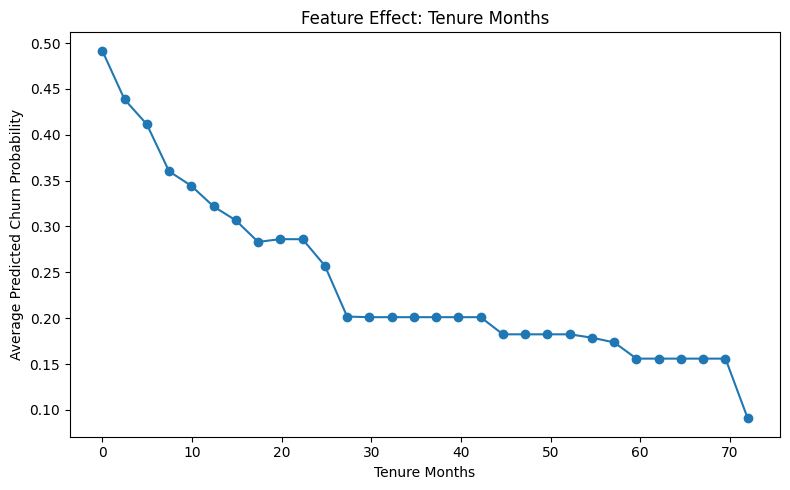

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create a copy of the test data
X_effect = X_test.copy()

# Range of tenure values
tenure_values = np.linspace(
    X_test["Tenure Months"].min(),
    X_test["Tenure Months"].max(),
    30
)

churn_probabilities = []

for tenure in tenure_values:
    X_temp = X_effect.copy()
    X_temp["Tenure Months"] = tenure

    # Average predicted probability of churn
    probability = gradient_boosting_pipeline.predict_proba(X_temp)[:, 1].mean()

    churn_probabilities.append(probability)

# Plot
plt.figure(figsize=(8, 5))

plt.plot(
    tenure_values,
    churn_probabilities,
    marker="o"
)

plt.xlabel("Tenure Months")
plt.ylabel("Average Predicted Churn Probability")
plt.title("Feature Effect: Tenure Months")

plt.tight_layout()
plt.show()

         Contract  Predicted Churn Probability
1  Month-to-month                     0.300497
2        One year                     0.203321
0        Two year                     0.127183


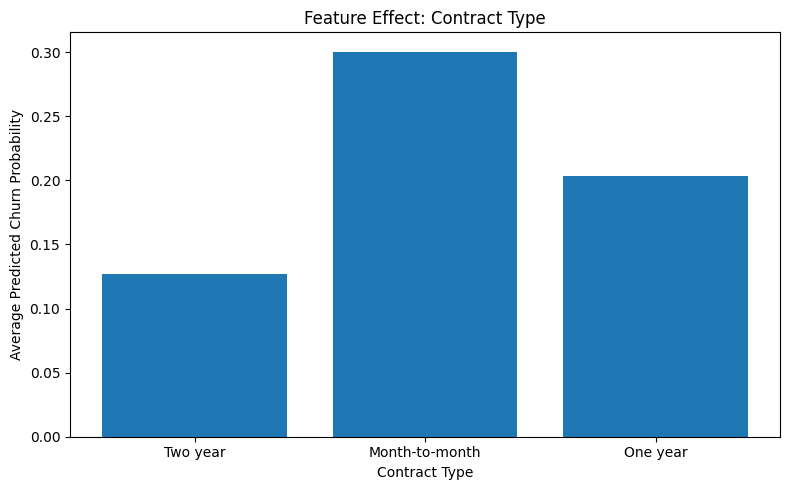

In [ ]:
contract_values = X_test["Contract"].unique()

contract_effect = []

for contract in contract_values:
    X_temp = X_test.copy()
    X_temp["Contract"] = contract

    probability = (
        gradient_boosting_pipeline
        .predict_proba(X_temp)[:, 1]
        .mean()
    )

    contract_effect.append({
        "Contract": contract,
        "Predicted Churn Probability": probability
    })

contract_effect_df = pd.DataFrame(contract_effect)

print(contract_effect_df.sort_values(
    "Predicted Churn Probability",
    ascending=False
))

# Plot
plt.figure(figsize=(8, 5))

plt.bar(
    contract_effect_df["Contract"],
    contract_effect_df["Predicted Churn Probability"]
)

plt.xlabel("Contract Type")
plt.ylabel("Average Predicted Churn Probability")
plt.title("Feature Effect: Contract Type")

plt.tight_layout()
plt.show()

  Internet Service  Predicted Churn Probability
0      Fiber optic                     0.326286
1              DSL                     0.208105
2               No                     0.195828


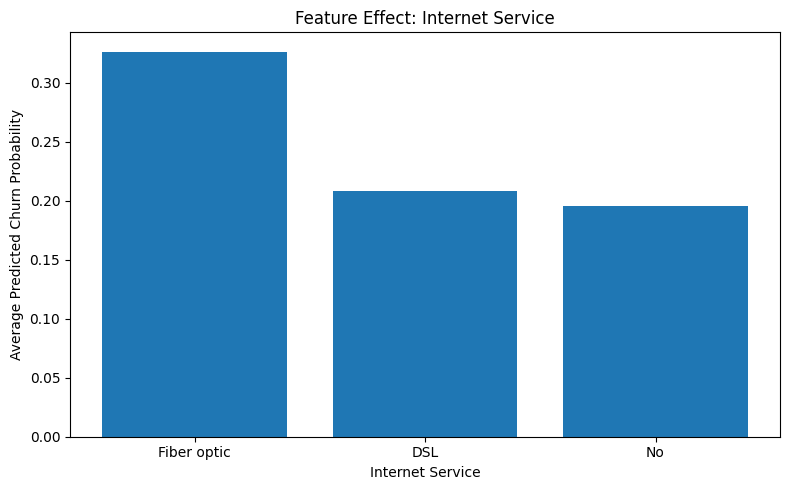

In [ ]:
internet_values = X_test["Internet Service"].unique()

internet_effect = []

for service in internet_values:
    X_temp = X_test.copy()
    X_temp["Internet Service"] = service

    probability = (
        gradient_boosting_pipeline
        .predict_proba(X_temp)[:, 1]
        .mean()
    )

    internet_effect.append({
        "Internet Service": service,
        "Predicted Churn Probability": probability
    })

internet_effect_df = pd.DataFrame(internet_effect)

print(internet_effect_df.sort_values(
    "Predicted Churn Probability",
    ascending=False
))

plt.figure(figsize=(8, 5))

plt.bar(
    internet_effect_df["Internet Service"],
    internet_effect_df["Predicted Churn Probability"]
)

plt.xlabel("Internet Service")
plt.ylabel("Average Predicted Churn Probability")
plt.title("Feature Effect: Internet Service")

plt.tight_layout()
plt.show()

  Dependents  Predicted Churn Probability
0         No                     0.294201
1        Yes                     0.142158


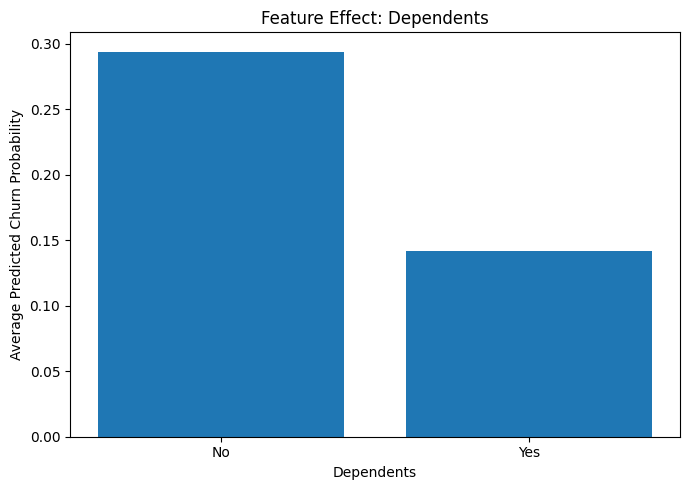

In [ ]:
dependent_values = X_test["Dependents"].unique()

dependent_effect = []

for dependent in dependent_values:
    X_temp = X_test.copy()
    X_temp["Dependents"] = dependent

    probability = (
        gradient_boosting_pipeline
        .predict_proba(X_temp)[:, 1]
        .mean()
    )

    dependent_effect.append({
        "Dependents": dependent,
        "Predicted Churn Probability": probability
    })

dependent_effect_df = pd.DataFrame(dependent_effect)

print(dependent_effect_df.sort_values(
    "Predicted Churn Probability",
    ascending=False
))

plt.figure(figsize=(7, 5))

plt.bar(
    dependent_effect_df["Dependents"],
    dependent_effect_df["Predicted Churn Probability"]
)

plt.xlabel("Dependents")
plt.ylabel("Average Predicted Churn Probability")
plt.title("Feature Effect: Dependents")

plt.tight_layout()
plt.show()

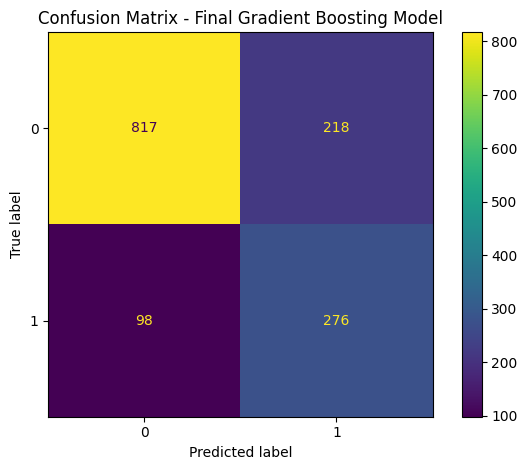

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_gb_final
)

plt.title("Confusion Matrix - Final Gradient Boosting Model")
plt.tight_layout()
plt.show()

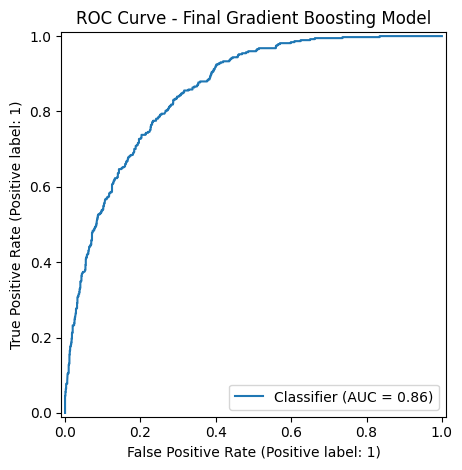

In [ ]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_gb_tuned
)

plt.title("ROC Curve - Final Gradient Boosting Model")
plt.tight_layout()
plt.show()

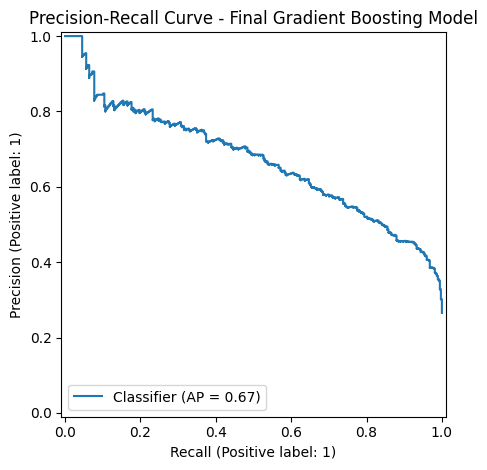

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob_gb_tuned
)

plt.title("Precision-Recall Curve - Final Gradient Boosting Model")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Decision Tree Tuned",
        "Random Forest",
        "Random Forest Tuned",
        "Gradient Boosting",
        "Gradient Boosting Tuned (0.50)",
        "Gradient Boosting Tuned (0.33)"
    ],
    "Accuracy": [
        0.80199,
        0.78779,
        0.79347,
        0.79418,
        0.80696,
        0.80341,
        0.80625,
        0.77573
    ],
    "Precision": [
        0.64264,
        0.59352,
        0.61625,
        0.63636,
        0.66667,
        0.66007,
        0.66777,
        0.55870
    ],
    "Recall": [
        0.57219,
        0.63636,
        0.58824,
        0.52406,
        0.54545,
        0.53476,
        0.53743,
        0.73797
    ],
    "F1": [
        0.60537,
        0.61419,
        0.60192,
        0.57478,
        0.60000,
        0.59084,
        0.59556,
        0.63594
    ],
    "ROC-AUC": [
        0.84905,
        0.82451,
        0.83051,
        0.83586,
        0.85195,
        0.85166,
        0.85522,
        0.85522
    ]
})

display(model_comparison)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.80199,0.64264,0.57219,0.60537,0.84905
1,Decision Tree,0.78779,0.59352,0.63636,0.61419,0.82451
2,Decision Tree Tuned,0.79347,0.61625,0.58824,0.60192,0.83051
3,Random Forest,0.79418,0.63636,0.52406,0.57478,0.83586
4,Random Forest Tuned,0.80696,0.66667,0.54545,0.60000,0.85195
5,Gradient Boosting,0.80341,0.66007,0.53476,0.59084,0.85166
6,Gradient Boosting Tuned (0.50),0.80625,0.66777,0.53743,0.59556,0.85522
7,Gradient Boosting Tuned (0.33),0.77573,0.55870,0.73797,0.63594,0.85522


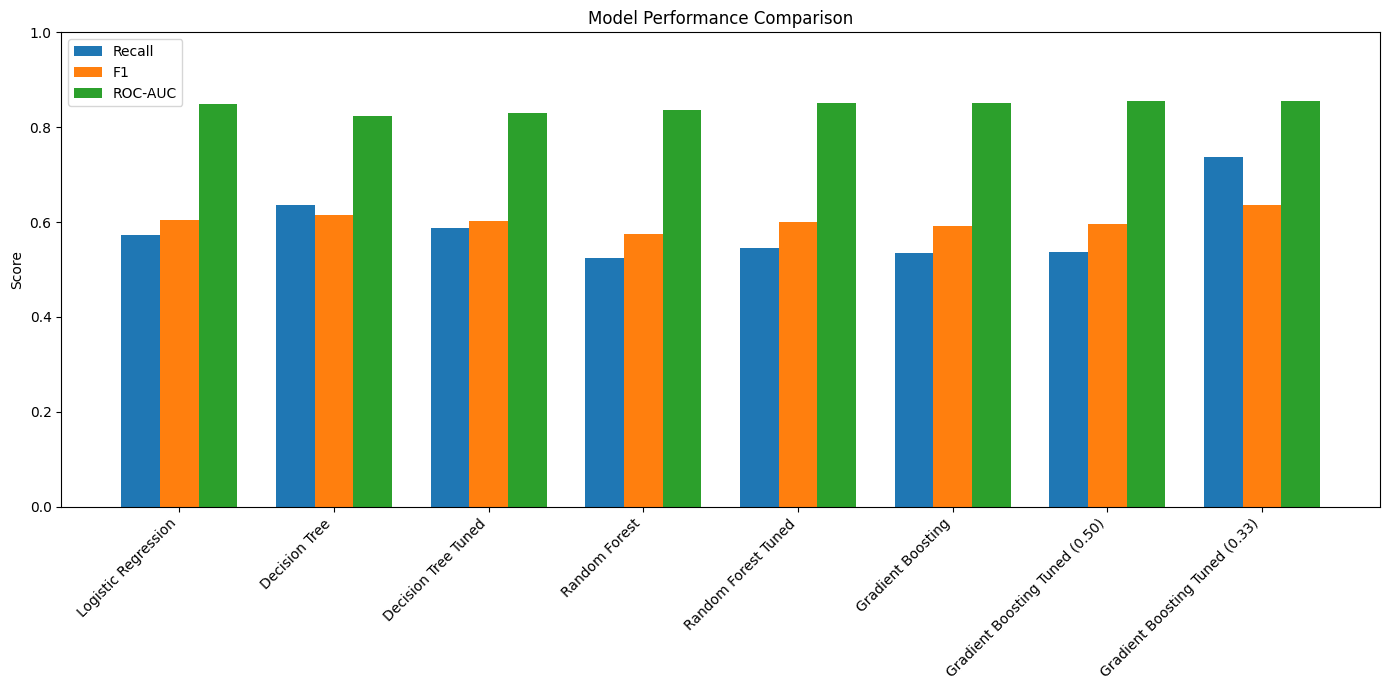

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = model_comparison["Model"]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(14, 7))

plt.bar(x - width, model_comparison["Recall"], width, label="Recall")
plt.bar(x, model_comparison["F1"], width, label="F1")
plt.bar(x + width, model_comparison["ROC-AUC"], width, label="ROC-AUC")

plt.xticks(x, models, rotation=45, ha="right")
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.ylim(0, 1)

plt.legend()
plt.tight_layout()
plt.show()

Business Recommendations
1. Prioritize new customers: Shorter-tenure customers showed higher predicted churn risk, suggesting that early onboarding and proactive support could be valuable.
2. Focus on month-to-month customers: Month-to-month customers received the highest average predicted churn probability. High-risk customers in this segment could be offered personalized retention options.
3. Investigate fiber-optic churn: Fiber-optic customers showed higher predicted churn risk. The company should investigate related factors such as pricing, service quality, and customer support rather than assuming fiber service itself causes churn.
4. Use risk-based targeting: Customers should be prioritized based on their predicted churn probability rather than on a single characteristic.
5. Use the model as a decision-support tool: The model should help the business identify customers who may need attention, while final retention decisions should consider customer circumstances and business costs.

## Conclusion

This project developed a machine learning model to predict customer churn using the IBM Telco Customer Churn dataset. The analysis began with data cleaning and exploratory data analysis to identify patterns associated with customer churn, followed by preprocessing, model training, hyperparameter tuning, and evaluation.

Several classification algorithms were evaluated, including Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting. The tuned Gradient Boosting model achieved the strongest ROC-AUC score of 0.8552, indicating good ability to distinguish between customers who churn and those who remain.

Because identifying potential churners was prioritized, classification threshold optimization was performed using out-of-fold validation data. A threshold of 0.33 was selected based on F1-score. When evaluated on the previously unseen test set, the final model achieved 77.57% accuracy, 55.87% precision, 73.80% recall, and 63.59% F1-score, with an ROC-AUC of 85.52%.

Model interpretation showed that Tenure Months, Contract, Internet Service, and Dependents were among the most important predictors. Feature-effect analysis indicated that shorter-tenure customers, month-to-month customers, fiber-optic customers, and customers without dependents generally received higher predicted churn probabilities.

These results suggest that the model could be used as a decision-support tool to identify customers who may require proactive retention attention. In particular, businesses could prioritize high-risk customers for appropriate onboarding, support, and retention strategies. However, the model identifies associations and predictions rather than causal relationships, so its predictions should be combined with business knowledge and customer-specific information.

Overall, the project demonstrates a complete machine learning workflow, from data exploration and preprocessing through model development, threshold optimization, evaluation, interpretation, and business recommendations.